# Train through a branch

> A model with an `if` on a learnable threshold has a gradient of exactly zero
> for that threshold. One option, `jump=`, gives it back, and plain gradient
> descent then finds the switch.

**Time:** ~8 min · **Runs on:** CPU · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`11_conditionals_budgets_events`, {doc}`../autodiff`

The sibling page {doc}`11_conditionals_budgets_events` differentiates a stop that falls between two steps. Here the discontinuity is in the model itself: a value that jumps when a parameter crosses a data point. The two pages are one family: a gradient that has to cross a discontinuity.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

## A threshold the loss cannot see

A sensor reads `x`; the model answers `a` below a threshold `t` and `b` above it. The data were made with `t = 0.3`, and we start from `t = -0.4`. As the kernel's author you write the branch the way you would anywhere else:

In [3]:
import tempfile

import numpy as np
import eagle

import hawk
from hawk import Mutable, Param, Scalar


def make(**options):
    @hawk.kernel(**options)
    def switch(x: Scalar, t: Param, a: Param, b: Param, y: Mutable[Scalar]):
        if x < t:
            y = a
        else:
            y = b
    return switch


n = 4096
x = np.random.default_rng(0).uniform(-1.0, 1.0, n)
A, B, T_TRUE = -0.5, 0.8, 0.3
target = np.where(x < T_TRUE, A, B)


def loss_and_grad(kernel):
    """A function t -> (mean squared error, dloss/dt), from one recorded launch and its reverse."""
    (plan,) = eagle.deploy([kernel], targets=("host",), cache_dir=tempfile.mkdtemp())

    def run(t):
        y = np.zeros(n)
        graph = eagle.Graph().add(plan.bind(x=x, t=t, a=A, b=B, y=y), name="s").build(record=True)
        graph.launch()
        grads = eagle.diff.Reverse(graph)(graph.record, {"s.y": 2 * (y - target) / n})
        return float(np.mean((y - target) ** 2)), float(grads["t"])
    return run


naive = loss_and_grad(make())
print("loss, d loss / d t at t = -0.4:", naive(-0.4))

loss, d loss / d t at t = -0.4: (0.5978540039062501, 0.0)


The loss is large and the gradient of `t` is exactly zero. That is correct for the program as written: `t` only chooses a branch, the branch values `a` and `b` do not depend on it, and moving `t` a little changes no output until it passes a sample. A gradient step would never move it.

## Give the jump a width

`jump=` smooths the switch for the derivative only. A sample within a few `width` of the threshold passes on the *jump* between the two branches, `a - b`, weighted by a bump of that width; farther samples cost one comparison. The kernel itself, its outputs and its digest are unchanged:

In [4]:
jumped = loss_and_grad(make(jump=0.05))
for t in (-0.4, 0.0, 0.3, 0.5):
    (l, g0), (_, g1) = naive(t), jumped(t)
    print(f"t = {t:4}: loss {l:.3f}   plain gradient {g0:6.3f}   jump= gradient {g1:6.3f}")

t = -0.4: loss 0.598   plain gradient  0.000   jump= gradient -0.842
t =  0.0: loss 0.243   plain gradient  0.000   jump= gradient -0.781
t =  0.3: loss 0.000   plain gradient  0.000   jump= gradient  0.000
t =  0.5: loss 0.164   plain gradient  0.000   jump= gradient  0.756


Same loss, same kernel, but now the gradient points downhill: negative left of the answer (raise `t`), positive right of it, and zero at `t = 0.3` where every sample is right. The picture shows both across a sweep of `t`:


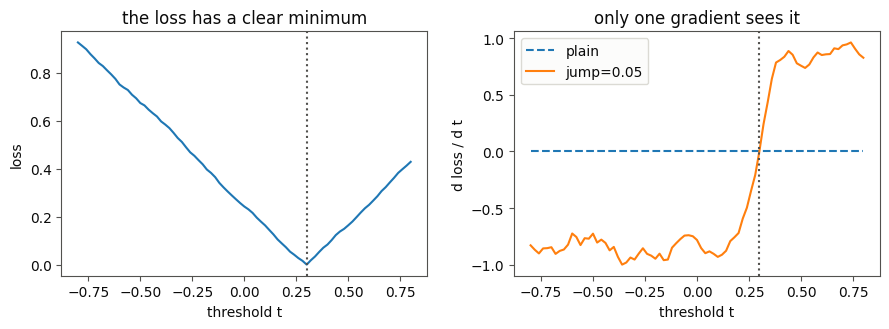
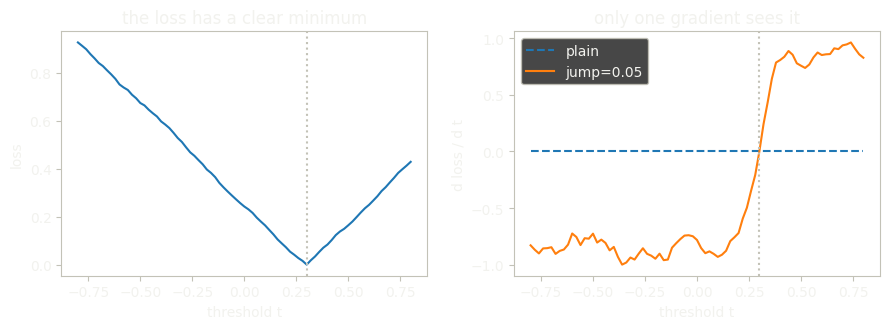

In [5]:
import matplotlib.pyplot as plt
from themed_figure import show

ts = np.linspace(-0.8, 0.8, 81)
plain = np.array([naive(t) for t in ts])
smooth = np.array([jumped(t) for t in ts])
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 3.4))
ax.plot(ts, plain[:, 0])
ax.axvline(T_TRUE, color="#898781", ls=":")
ax.set(xlabel="threshold t", ylabel="loss", title="the loss has a clear minimum")
bx.plot(ts, plain[:, 1], "--", label="plain")
bx.plot(ts, smooth[:, 1], label="jump=0.05")
bx.axvline(T_TRUE, color="#898781", ls=":")
bx.set(xlabel="threshold t", ylabel="d loss / d t", title="only one gradient sees it")
bx.legend()
plt.tight_layout()
show()

## Train it

Plain gradient descent on `t`, starting well away from the answer:

t after 16 steps: 0.3003   (data made with 0.3)



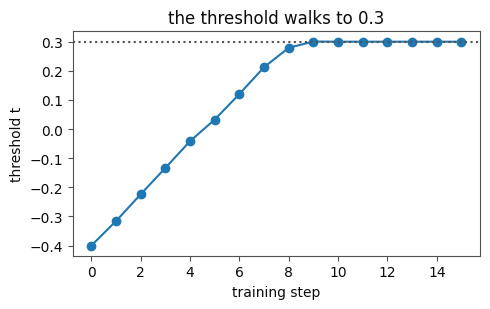
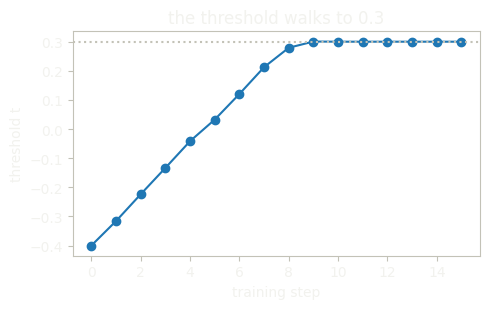

In [6]:
from themed_figure import show
t, history = -0.4, []
for step in range(16):
    l, g = jumped(t)
    history.append((t, l))
    t -= 0.1 * g
print(f"t after 16 steps: {t:.4f}   (data made with {T_TRUE})")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot([h[0] for h in history], "o-")
ax.axhline(T_TRUE, color="#898781", ls=":")
ax.set(xlabel="training step", ylabel="threshold t", title="the threshold walks to 0.3")
plt.tight_layout()
show()

The threshold crosses the data in about eight steps and settles at the generating value. Each step cost one launch and one reverse, the same as any other trained parameter.

The width is the one choice to make. A wider `width` reaches a threshold that is further away and gives a smoother gradient; a narrower one is sharper but sees only samples close to the switch. `jump="auto"` picks it from the batch, and `jump="h"` reads it from a `Param` you can change between launches without a rebuild. A comparison with `==`, or a `break` that depends on the compared value, is refused by name. The full list is in the hawk docs; the stop-time version of the same problem is in {doc}`11_conditionals_budgets_events`, with its reference in {ref}`autodiff-events`.